# Analysis on how prescribed fire impacts vegetation responses 2002(Dry) vs 2003(Wet)

# North AOI

## Import libraries

In [1]:
import os
import arcpy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import utils
#import importlib
#importlib.reload(utils)

## Configurations

In [2]:
# GDB and GEE data paths
data_root_dir = r"C:\Users\Huiting Huang\Documents\GIS_Certificate_2025_26\ArcGIS_Projects\EvaluatingForestDisturbances"
gdb_path = os.path.join(data_root_dir, "EvaluatingForestDisturbances.gdb")
gee_landsat_dir = os.path.join(data_root_dir, "Data", "GEE_Landsat")

# Area of interest and processing extent
aoi = "North"
extent = "TNC_AOIs_North"

## Set geoprocessing environment

In [3]:
arcpy.env.workspace = gdb_path
arcpy.env.extent = extent

## Comparison of vegetation responses between burned areas and unburned areas

### Utility functions

In [4]:
def create_zonal_stats_pairs(year, time_period, composite_strategy, vegetation_index, aoi, forest_type_raster_ori, forest_type_labels):
    """Match vegetation and forest-type rasters by TSF and calculate zonal statistics by forest type in each TSF .

    Raster datasets are selected from the current ArcPy workspace using the
    supplied naming components. For each vegetation raster, the function
    finds the forest-type raster with the same final TSF filename component
    and extracts vegetation values for each forest type.

    Parameters
    ----------
    year : str
        Year token used to select both raster datasets.
    time_period : str
        Time-period token in vegetation raster names, such as ``06To08``.
    composite_strategy : str
        Composite method in vegetation raster names, such as ``Max``.
    vegetation_index : str
        Vegetation index in raster names, such as ``NDVI``, ``NDMI``, or ``EVI``.
    aoi : str
        Area-of-interest token in vegetation raster names.
    forest_type_raster_ori : str
        Prefix used to select forest-type rasters.
    forest_type_labels : dict
        Mapping of forest-type raster values to labels, passed to
        ``utils.zonal_stats``.

    Returns
    -------
    tuple[dict, dict]
        ``(forest_type_vegetation_pairs, zonal_stat_pairs)``:
        - ``forest_type_vegetation_pairs`` maps matched forest-type raster names
          to vegetation raster names by TSF.
        - ``zonal_stat_pairs`` maps TSF labels to lists of arrays containing
          vegetation values grouped by forest type, ordered according to ``forest_type_labels``.

    Raises
    ------
    RuntimeError
        If no vegetation/forest-type raster pair with a matching TSF is found.
    """
    vegetation_raster_filter = f"{composite_strategy}_{vegetation_index}_{year}_{time_period}_{aoi}_30m_*"
    forest_type_raster_filter = f"{forest_type_raster_ori}_{year}_*"
    all_vegetation_rasters = sorted(arcpy.ListRasters(vegetation_raster_filter) or [])
    all_forest_type_rasters = sorted(arcpy.ListRasters(forest_type_raster_filter) or [])

    # Store each matched forest-type raster and its vegetation raster by TSF.
    forest_type_vegetation_pairs = {}
    # Store zonal vegetation values for each TSF, grouped by forest type.
    zonal_stat_pairs = {}
    for vegetation_raster in all_vegetation_rasters:
        tsf = vegetation_raster.rsplit("_", 1)[-1]
        matched_forest_type = None
        for forest_type_raster in all_forest_type_rasters:
            forest_type_tsf = forest_type_raster.rsplit("_", 1)[-1]
            if forest_type_tsf == tsf:
                matched_forest_type = forest_type_raster
                break

        if matched_forest_type is None:
            print(f"No matched forest-type raster for {vegetation_raster}")
            continue

        forest_type_vegetation_pairs[matched_forest_type] = vegetation_raster
        data, _ = utils.zonal_stats(vegetation_raster, matched_forest_type, forest_type_labels)
        zonal_stat_pairs[tsf] = data

    if not zonal_stat_pairs:
        raise RuntimeError("No vegetation rasters could be matched with forest-type rasters.")

    return forest_type_vegetation_pairs, zonal_stat_pairs

In [5]:
def calculate_zonal_means(zonal_stat_pairs, forest_type_labels):
    """Calculate mean vegetation-index values for each TSF and forest type.

    Parameters
    ----------
    zonal_stat_pairs : dict
        Mapping of TSF labels to lists of pixel-value arrays, ordered by the
        forest-type codes in ``forest_type_labels``.
    forest_type_labels : dict
        Mapping of forest-type codes to display labels, such as
        ``{1: "Cool", 2: "Intermediate", 3: "Hot"}``.

    Returns
    -------
    dict
        Nested mapping of TSF labels and forest-type labels to their mean
        vegetation-index values. TSF labels beginning with ``"unburn"`` are
        normalized to ``"Unburned"``.
    """
    means_by_tsf = {}

    for tsf, values_by_forest_type in zonal_stat_pairs.items():
        tsf_label = "Unburned" if tsf.lower().startswith("unburn") else tsf
        means_by_tsf[tsf_label] = {}
        for i, forest_type in enumerate(forest_type_labels.values()):
            means_by_tsf[tsf_label][forest_type] = np.mean(values_by_forest_type[i])

    return means_by_tsf

In [11]:
def create_vegetation_index_bar_chart(zonal_stat_pairs, forest_type_labels, year_label, composite_strategy, vegetation_index):
    """Plot mean vegetation-index values by TSF and forest type.

    Each entry in ``zonal_stat_pairs`` contains one array of pixel values per
    forest type, in the order defined by ``forest_type_labels``. The function
    calculates the mean of each array and displays grouped bars for each TSF.

    Parameters
    ----------
    zonal_stat_pairs : dict
        Mapping of TSF labels to lists of vegetation-value arrays, ordered by
        the forest-type codes in ``forest_type_labels``.
    forest_type_labels : dict
        Mapping of forest-type codes to display labels, such as
        ``{1: "Cool", 2: "Intermediate", 3: "Hot"}``.
    year_label : str
        Year/season text included in the plot title, such as ``"2002 Dry"``.
    composite_strategy : str
        Composite method included in the plot title, such as ``"Max"``.
    vegetation_index : str
        Vegetation index used for the y-axis label and plot title, such as
        ``"NDVI"``, ``"NDMI"``, or ``"EVI"``.

    Returns
    -------
    tuple
        The Matplotlib ``(fig, ax)`` figure and axes objects.
    """
    fig, ax = plt.subplots(figsize=(10, 4))

    means_by_tsf = calculate_zonal_means(zonal_stat_pairs, forest_type_labels)

    # Prepare TSF groups and draw offset, color-coded mean bars for each forest type.
    # tsf_labels = list(means_by_tsf.keys())
    tsf_labels = sorted(
        means_by_tsf,
        key=lambda tsf: (tsf != "Unburned", tsf),
    )
    x = np.arange(len(tsf_labels))
    n_forest_types = len(forest_type_labels)
    bar_width = 0.2
    color = {"Cool": "Blue", "Intermediate": "Green", "Hot": "Orange"}
    for i, label in enumerate(forest_type_labels.values()):
        offset = (i - n_forest_types / 2) * bar_width + bar_width / 2
        means = [means_by_tsf[tsf][label] for tsf in tsf_labels]
        bars = ax.bar(x + offset, means, label=label, width=bar_width, color=color[label], alpha=0.7)
        ax.bar_label(bars, fmt="%.3f", padding=3, rotation=40)
    
    # Set x-ticks and labels, y-axis label, title, legend, and grid.  
    ax.set_xticks(x)
    ax.set_xticklabels(tsf_labels)
    ax.set_xlabel("Time Since Fire (TSF)")
    ax.set_ylabel(vegetation_index)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
    ax.set_title(f"Mean Value of {composite_strategy} {vegetation_index} Composite by TSF and Forest Type ({year_label})")
    ax.legend(title="Forest Type", loc="upper left", bbox_to_anchor=(1, 1))
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    fig.tight_layout()

    return fig, ax

### Parameters

In [7]:
forest_type_labels = {1: "Cool", 2: "Intermediate", 3: "Hot"}
forest_type_raster_ori = "fortype_aoiN_UTM_30m"

# Store mean vegetation-index values by TSF and forest type for each year.
zonal_means = {}

### NDVI

In [8]:
# Parameters
composite_strategy = "Max" # Max, Mean, Median
vegetation_index = "NDVI"; # NDVI, NDMI, EVI

#### 2002(Dry)

In [9]:
year = "2002"
time_period = "06To08"
forest_type_vegetation_pairs, zonal_stat_pairs = create_zonal_stats_pairs(year, time_period, composite_strategy, vegetation_index, aoi, forest_type_raster_ori, forest_type_labels)
zonal_means[(year, vegetation_index)] = calculate_zonal_means(zonal_stat_pairs, forest_type_labels)

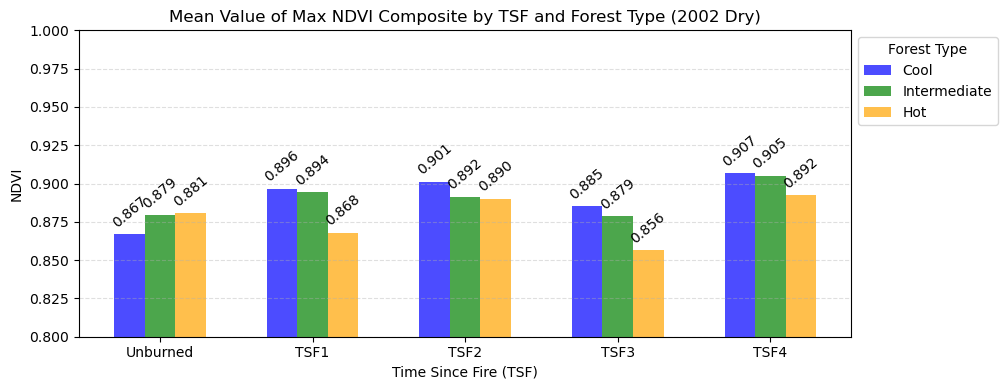

In [12]:
year_label = "2002 Dry"
fig, ax = create_vegetation_index_bar_chart(zonal_stat_pairs, forest_type_labels, year_label, composite_strategy, vegetation_index)
ax.set_ylim(0.8, 1);

#### 2003(Wet)

In [13]:
year = "2003"
time_period = "06To08"
forest_type_vegetation_pairs, zonal_stat_pairs = create_zonal_stats_pairs(year, time_period, composite_strategy, vegetation_index, aoi, forest_type_raster_ori, forest_type_labels)
zonal_means[(year, vegetation_index)] = calculate_zonal_means(zonal_stat_pairs, forest_type_labels)

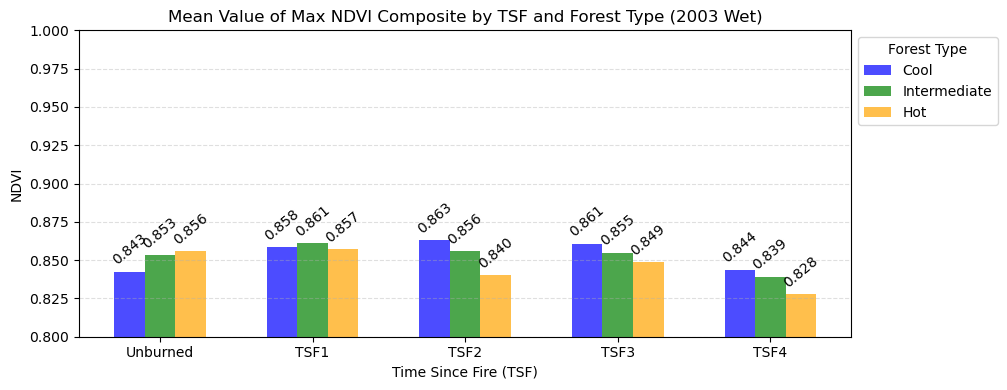

In [14]:
year_label = "2003 Wet"
fig, ax = create_vegetation_index_bar_chart(zonal_stat_pairs, forest_type_labels, year_label, composite_strategy, vegetation_index)
ax.set_ylim(0.8, 1);

### NDMI

In [15]:
# Parameters
composite_strategy = "Max" # Max, Mean, Median
vegetation_index = "NDMI"; # NDVI, NDMI, EVI

#### 2002 (Dry)

In [16]:
year = "2002"
time_period = "06To08"
forest_type_vegetation_pairs, zonal_stat_pairs = create_zonal_stats_pairs(year, time_period, composite_strategy, vegetation_index, aoi, forest_type_raster_ori, forest_type_labels)
zonal_means[(year, vegetation_index)] = calculate_zonal_means(zonal_stat_pairs, forest_type_labels)

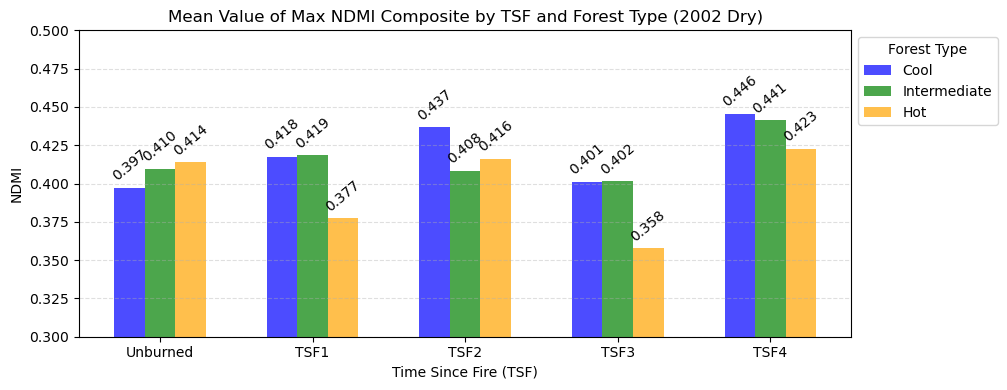

In [17]:
year_label = "2002 Dry"
fig, ax = create_vegetation_index_bar_chart(zonal_stat_pairs, forest_type_labels, year_label, composite_strategy, vegetation_index)
ax.set_ylim(0.3, 0.5);

#### 2003 (Wet)

In [18]:
year = "2003"
time_period = "06To08"
forest_type_vegetation_pairs, zonal_stat_pairs = create_zonal_stats_pairs(year, time_period, composite_strategy, vegetation_index, aoi, forest_type_raster_ori, forest_type_labels)
zonal_means[(year, vegetation_index)] = calculate_zonal_means(zonal_stat_pairs, forest_type_labels)

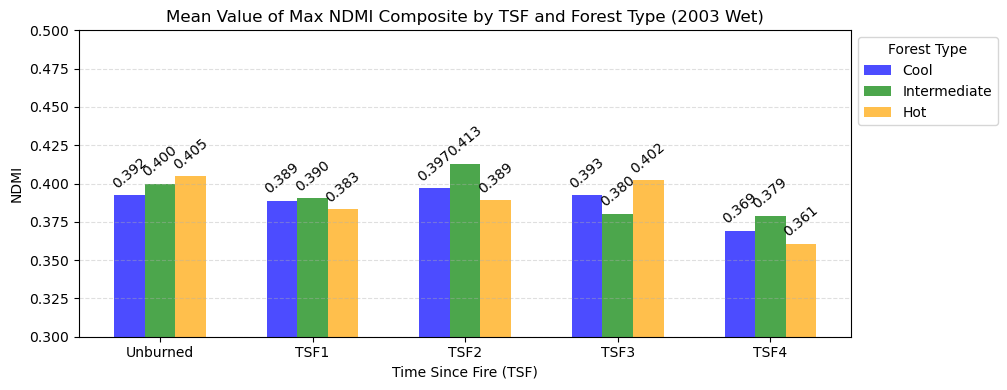

In [19]:
year_label = "2003 Wet"
fig, ax = create_vegetation_index_bar_chart(zonal_stat_pairs, forest_type_labels, year_label, composite_strategy, vegetation_index)
ax.set_ylim(0.3, 0.5);

### EVI

In [20]:
# Parameters
composite_strategy = "Max" # Max, Mean, Median
vegetation_index = "EVI"; # NDVI, NDMI, EVI

#### 2002 (Dry)

In [21]:
year = "2002"
time_period = "06To08"
forest_type_vegetation_pairs, zonal_stat_pairs = create_zonal_stats_pairs(year, time_period, composite_strategy, vegetation_index, aoi, forest_type_raster_ori, forest_type_labels)
zonal_means[(year, vegetation_index)] = calculate_zonal_means(zonal_stat_pairs, forest_type_labels)

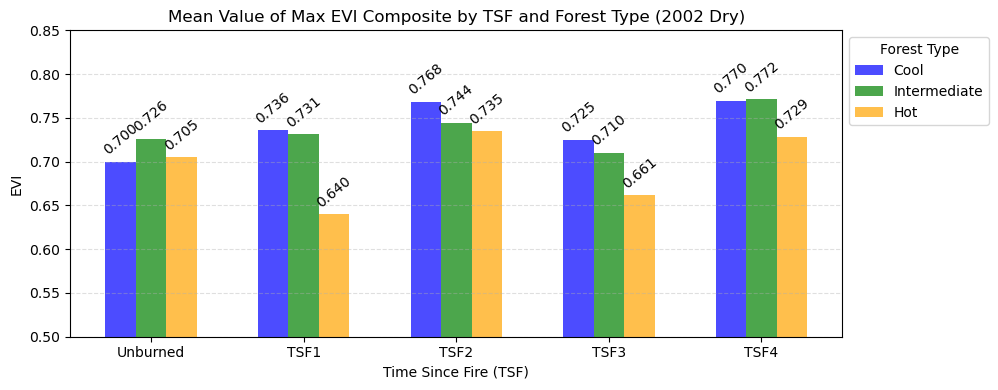

In [22]:
year_label = "2002 Dry"
fig, ax = create_vegetation_index_bar_chart(zonal_stat_pairs, forest_type_labels, year_label, composite_strategy, vegetation_index)
ax.set_ylim(0.5, 0.85);

#### 2003 (Wet)

In [23]:
year = "2003"
time_period = "06To08"
forest_type_vegetation_pairs, zonal_stat_pairs = create_zonal_stats_pairs(year, time_period, composite_strategy, vegetation_index, aoi, forest_type_raster_ori, forest_type_labels)
zonal_means[(year, vegetation_index)] = calculate_zonal_means(zonal_stat_pairs, forest_type_labels)

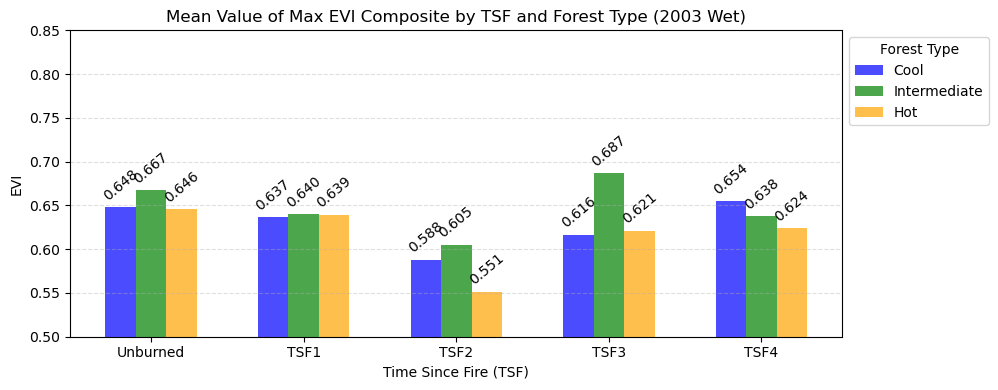

In [24]:
year_label = "2003 Wet"
fig, ax = create_vegetation_index_bar_chart(zonal_stat_pairs, forest_type_labels, year_label, composite_strategy, vegetation_index)
ax.set_ylim(0.5, 0.85);

## Comparison between dry and wet years: vegetation index change (2002 Dry − 2003 Wet) by TSF class and forest type

### Data preparation

In [26]:
# Build the dry-versus-wet comparison table from zonal means.
class_order = ["Unburned", "TSF1", "TSF2", "TSF3", "TSF4"]
forest_types = list(forest_type_labels.values())
vegetation_indices = ["NDVI", "NDMI", "EVI"]
rows = []

for tsf in class_order:
    for forest_type in forest_types:
        row = {"Class": tsf, "Forest type": forest_type}
        for vegetation_index in vegetation_indices:
            dry_mean = zonal_means[("2002", vegetation_index)][tsf][forest_type]
            wet_mean = zonal_means[("2003", vegetation_index)][tsf][forest_type]
            difference = dry_mean - wet_mean
            if wet_mean == 0:
                raise ZeroDivisionError(f"Cannot calculate {vegetation_index} percentage change for {tsf}/{forest_type}: 2003 mean is zero.")

            row[f"Dry(2002) {vegetation_index}"] = dry_mean
            row[f"Wet(2003) {vegetation_index}"] = wet_mean
            row[f"{vegetation_index} Diff"] = difference
            row[f"{vegetation_index} PCT Change(%)"] = difference / wet_mean * 100

        rows.append(row)

df = pd.DataFrame(rows)
df = df.round(3)
display(df)

,Class,Forest type,Dry(2002) NDVI,Wet(2003) NDVI,NDVI Diff,NDVI PCT Change(%),Dry(2002) NDMI,Wet(2003) NDMI,NDMI Diff,NDMI PCT Change(%),Dry(2002) EVI,Wet(2003) EVI,EVI Diff,EVI PCT Change(%)
0,Unburned,Cool,0.867,0.843,0.024,2.892,0.397,0.392,0.005,1.268000,0.700,0.648,0.052,7.998
1,Unburned,Intermediate,0.879,0.853,0.026,3.036,0.410,0.400,0.010,2.463000,0.726,0.667,0.059,8.843
2,Unburned,Hot,0.881,0.856,0.025,2.898,0.414,0.405,0.009,2.234000,0.705,0.646,0.059,9.189
3,TSF1,Cool,0.896,0.858,0.038,4.441,0.418,0.389,0.029,7.384000,0.736,0.637,0.099,15.550
4,TSF1,Intermediate,0.894,0.861,0.033,3.870,0.419,0.390,0.028,7.257000,0.731,0.640,0.092,14.321
5,TSF1,Hot,0.868,0.857,0.011,1.241,0.377,0.383,-0.006,-1.535000,0.640,0.639,0.001,0.090
6,TSF2,Cool,0.901,0.863,0.038,4.423,0.437,0.397,0.040,10.039000,0.768,0.588,0.181,30.730
7,TSF2,Intermediate,0.892,0.856,0.036,4.168,0.408,0.413,-0.004,-1.082000,0.744,0.605,0.139,23.036
8,TSF2,Hot,0.890,0.840,0.050,5.929,0.416,0.389,0.027,6.929000,0.735,0.551,0.183,33.235
9,TSF3,Cool,0.885,0.861,0.024,2.819,0.401,0.393,0.009,2.170000,0.725,0.616,0.108,17.586


### Utility funtions

In [27]:
# Plot vegetation-index changes by TSF and forest type.
colors = {"Cool": "Blue", "Intermediate": "Green", "Hot": "Orange"}

def create_vegetation_change_bar_chart(data_frame, column_name, y_label, title, bar_width=0.25):
    """Plot vegetation-index changes by TSF and forest type.

    Parameters
    ----------
    data_frame : pandas.DataFrame
        Comparison data containing class, forest type, and change values.
    column_name : str
        Name of the change column to plot.
    y_label : str
        Label for the y-axis.
    title : str
        Plot title.
    bar_width : float, optional
        Width of each bar. Defaults to 0.25.

    Returns
    -------
    tuple
        The Matplotlib figure and axes objects.
    """
    fig, ax = plt.subplots(figsize=(8, 3))
    x = np.arange(len(class_order))
    bars_by_forest_type = []

    for i, forest_type in enumerate(forest_types):
        forest_type_data = (
            data_frame[data_frame["Forest type"] == forest_type]
            .set_index("Class")
            .reindex(class_order)
        )
        values = forest_type_data[column_name].values
        offset = (i - (len(forest_types) - 1) / 2) * bar_width
        bars = ax.bar(
            x + offset,
            values,
            bar_width,
            label=forest_type,
            color=colors[forest_type],
            alpha=0.7,
        )
        bars_by_forest_type.append(bars)

    for bars in bars_by_forest_type:
        ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(class_order)
    ax.set_xlabel("Time Since Fire (TSF)")
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(title="Forest Type", loc="upper left", bbox_to_anchor=(1, 1))
    plt.tight_layout()

    return fig, ax

### NDVI

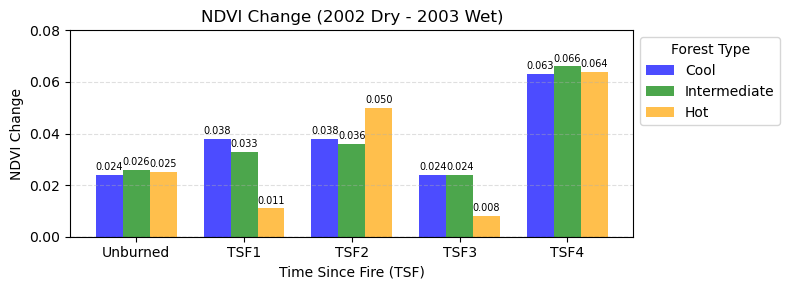

In [28]:
fig, ax = create_vegetation_change_bar_chart(df, "NDVI Diff", "NDVI Change", "NDVI Change (2002 Dry - 2003 Wet)")
ax.set_ylim(0, 0.08);

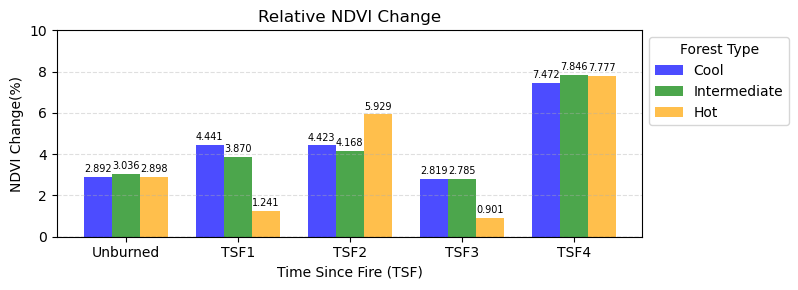

In [29]:
fig, ax = create_vegetation_change_bar_chart(df, "NDVI PCT Change(%)", "NDVI Change(%)", "Relative NDVI Change")
ax.set_ylim(0, 10);

### NDMI

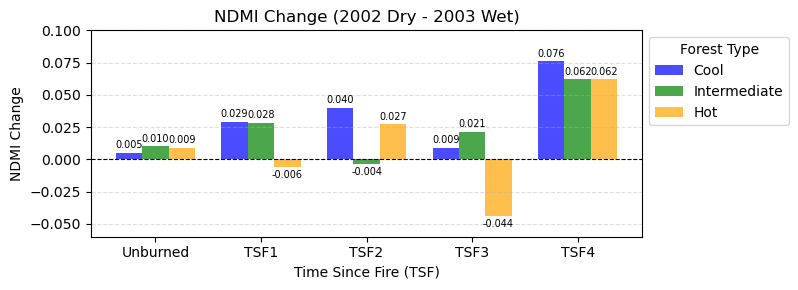

In [30]:
fig, ax = create_vegetation_change_bar_chart(df, "NDMI Diff", "NDMI Change", "NDMI Change (2002 Dry - 2003 Wet)")
ax.set_ylim(-0.06, 0.10);

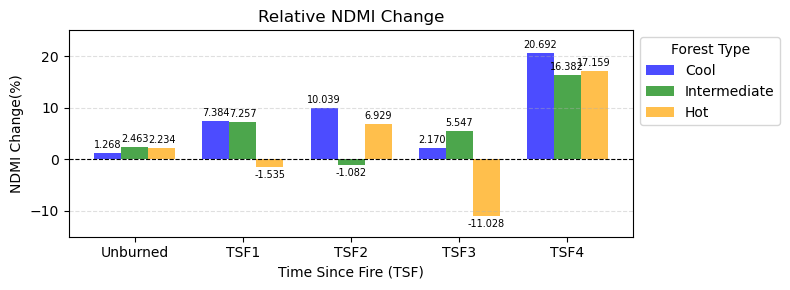

In [31]:
fig, ax = create_vegetation_change_bar_chart(df, "NDMI PCT Change(%)", "NDMI Change(%)", "Relative NDMI Change")
ax.set_ylim(-15.0, 25.0);

### EVI

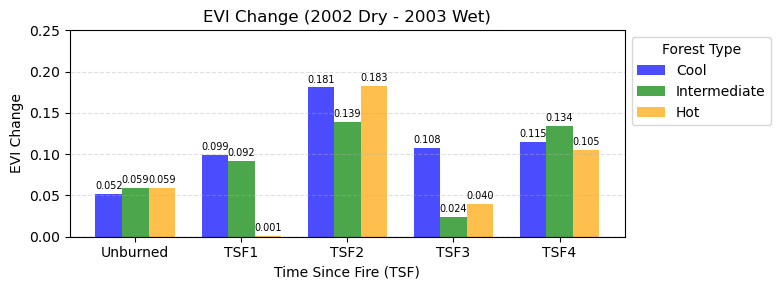

In [32]:
fig, ax = create_vegetation_change_bar_chart(df, "EVI Diff", "EVI Change", "EVI Change (2002 Dry - 2003 Wet)")
ax.set_ylim(0, 0.25);

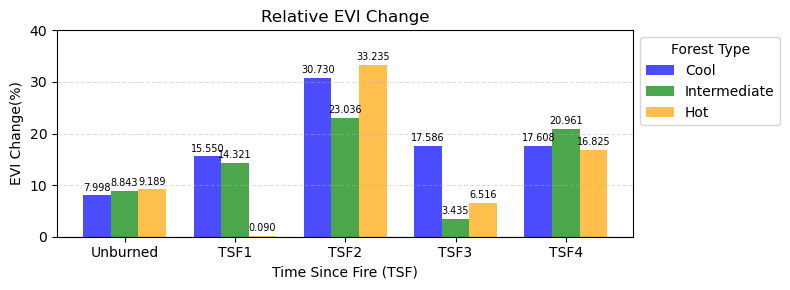

In [33]:
fig, ax = create_vegetation_change_bar_chart(df, "EVI PCT Change(%)", "EVI Change(%)", "Relative EVI Change")
ax.set_ylim(0, 40.0);